In [36]:
import json


In [37]:
with open("./exp/exp_all/result.json", "r", encoding="utf-8") as f:
    data = json.load(f)

total_input_tokens = 0
total_output_tokens = 0
for d in data:
    total_input_tokens += d["input_tokens"]
    total_output_tokens += d["output_tokens"]

print(f"总输入token数: {total_input_tokens}, 总输出token数: {total_output_tokens}")
print(f"平均输入token数: {total_input_tokens / len(data)}, 平均输出token数: {total_output_tokens / len(data)}")

总输入token数: 2557773, 总输出token数: 1474637
平均输入token数: 1281.4493987975952, 平均输出token数: 738.7960921843687


In [38]:
"""
2B&4B:

We recommend using the following set of sampling parameters for generation

Non-thinking mode for text tasks: temperature=1.0, top_p=1.00, top_k=20, min_p=0.0, presence_penalty=2.0, repetition_penalty=1.0
Non-thinking mode for VL tasks: temperature=0.7, top_p=0.8, top_k=20, min_p=0.0, presence_penalty=1.5, repetition_penalty=1.0
Thinking mode for text tasks: temperature=1.0, top_p=0.95, top_k=20, min_p=0.0, presence_penalty=1.5, repetition_penalty=1.0
Thinking mode for VL or precise coding (e.g. WebDev) tasks : temperature=0.6, top_p=0.95, top_k=20, min_p=0.0, presence_penalty=0.0, repetition_penalty=1.0
Please note that the support for sampling parameters varies according to inference frameworks.
"""

'\n2B&4B:\n\nWe recommend using the following set of sampling parameters for generation\n\nNon-thinking mode for text tasks: temperature=1.0, top_p=1.00, top_k=20, min_p=0.0, presence_penalty=2.0, repetition_penalty=1.0\nNon-thinking mode for VL tasks: temperature=0.7, top_p=0.8, top_k=20, min_p=0.0, presence_penalty=1.5, repetition_penalty=1.0\nThinking mode for text tasks: temperature=1.0, top_p=0.95, top_k=20, min_p=0.0, presence_penalty=1.5, repetition_penalty=1.0\nThinking mode for VL or precise coding (e.g. WebDev) tasks : temperature=0.6, top_p=0.95, top_k=20, min_p=0.0, presence_penalty=0.0, repetition_penalty=1.0\nPlease note that the support for sampling parameters varies according to inference frameworks.\n'

In [39]:
with open("./anno/instance_data.json", "r", encoding="utf-8") as f:
    data = json.load(f)
data[0]

{'image_name': '0000-fsc147-1106.jpg',
 'caption': 'red pen',
 'category': 'pen',
 'attributes': 'red',
 'point': [155.36, 48.55],
 'type': 'color',
 'instance_id': 0,
 'image_idx': 0,
 'caption_idx': 0,
 'point_idx': 0}

In [40]:
category_dict = {}
for item in data:
    if item["category"] not in category_dict:
        category_dict[item["category"]] = 1
    else:
        category_dict[item["category"]] += 1
# print(category_dict)

In [41]:
# 按照数量排序输出
sorted_category_dict = sorted(category_dict.items(), key=lambda x: x[1], reverse=True)
print(sorted_category_dict)

[('person', 196589), ('car', 54219), ('go stone', 2690), ('bottle cap', 1717), ('coin', 1564), ('bead', 1410), ('pen', 1386), ('pill', 1347), ('grape', 1206), ('book', 1146), ('apple', 1112), ('tile', 1052), ('box', 1045), ('cap', 1041), ('nail polish', 1026), ('egg', 813), ('key', 770), ('can', 761), ('bottle', 705), ('tomato', 705), ('cup', 701), ('ball', 541), ('wine bottle', 535), ('sticker', 533), ('green pea', 528), ('pencil', 487), ('shirt', 475), ('straw', 432), ('lip stick', 429), ('strawberry', 423), ('shoe box', 413), ('milk bottle', 403), ('candle', 387), ('stamp', 347), ('cassette', 308), ('bird', 295), ('candy', 291), ('capsule', 263), ('brick', 259), ('cartridge', 259), ('crayon', 255), ('glasses', 238), ('fruit', 230), ('donut', 222), ('orange', 221), ('fruit box', 219), ('coffee bean', 216), ('glass ball', 197), ('chair', 180), ('fish', 170), ('bag', 164), ('bowl', 159), ('sunglasses', 148), ('packet', 145), ('sneaker', 137), ('kidney bean', 133), ('flower pot', 128), 

In [42]:
animal_keys = ["elephant", "cow", "camel", "penguin", "fish", "zebra", "bird", "goat", "swan", "flamingo", "horse",
               "ant"]

person_count = category_dict["person"]
car_count = category_dict["car"]

animal_count = sum([category_dict[key] for key in animal_keys])

other_count = sum([category_dict[key] for key in category_dict]) - person_count - car_count - animal_count

print(person_count)
print(car_count)
print(animal_count)
print(other_count)

196589
54219
858
34955


In [43]:
attribute_dict = {}
for item in data:
    if item["attributes"] not in attribute_dict:
        attribute_dict[item["attributes"]] = 1
    else:
        attribute_dict[item["attributes"]] += 1
# print(attribute_dict)

In [44]:
# 按照数量排序输出
sorted_attribute_dict = sorted(attribute_dict.items(), key=lambda x: x[1], reverse=True)
print(sorted_attribute_dict)

[('standing', 40356), ('walking', 28259), ('sitting', 26862), ('female', 16732), ('adult', 15533), ('in queue', 14184), ('white', 9683), ('driving to the left', 9559), ('driving downward', 9145), ('driving upward', 8693), ('black', 8435), ('driving to the right', 7832), ('male', 7626), ('elderly', 7534), ('red', 3848), ('gray', 3218), ('blue', 2944), ('yellow', 2173), ('crossing the road', 2166), ('green', 1954), ('on the top side walk', 1579), ('dancing', 1550), ('approaching', 1320), ('wearing a green shirt', 1147), ('walking away', 1145), ('running', 1073), ('walking to the left', 1072), ('wearing a white shirt', 1012), ('kid', 1000), ('in a queue', 954), ('walking to the right', 943), ('wearing a blue shirt', 905), ('silver', 875), ('changing lane', 804), ('sitting in a chair', 783), ('on the left side walk', 764), ('copper', 751), ('on the bottom right side walk', 739), ('watching', 727), ('brown', 667), ('on the ground', 625), ('in the queue', 606), ('in the top layer', 580), ('o

In [45]:
with open("./exp/exp_local_qwen35_2B/result.json", "r", encoding="utf-8") as f:
    data_student = json.load(f)

# with open("./exp/exp_local_qwen35_4B/result.json", "r", encoding="utf-8") as f:
#     data_student = json.load(f)

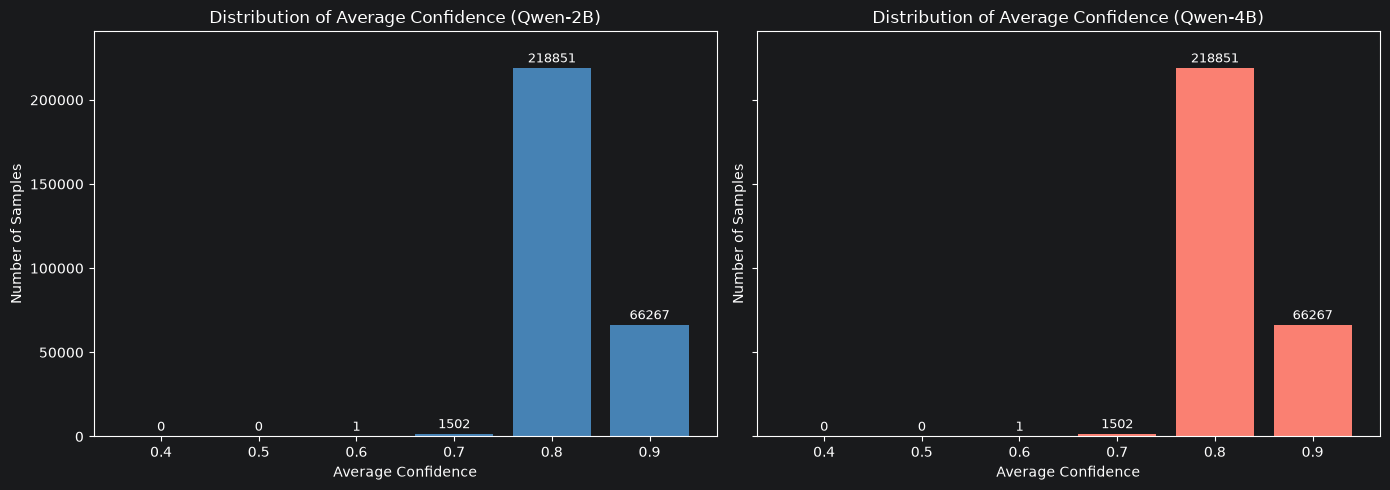

In [46]:
import matplotlib.pyplot as plt

# 各区间计数
bins = [str(i / 10) for i in range(4, 10)]
counts_2b = [sum(1 for d in data_student if round(d["average_confidence"], 1) == i / 10) for i in range(4, 10)]
counts_4b = [sum(1 for d in data_student if round(d["average_confidence"], 1) == i / 10) for i in range(4, 10)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, counts, name, color in zip(
        axes,
        [counts_2b, counts_4b],
        ["Qwen-2B", "Qwen-4B"],
        ["steelblue", "salmon"],
):
    bars = ax.bar(bins, counts, color=color)
    # 在柱顶显示数值
    ax.bar_label(bars, labels=[str(c) for c in counts], padding=2, fontsize=9)
    ax.set_xlabel("Average Confidence")
    ax.set_ylabel("Number of Samples")
    ax.set_title(f"Distribution of Average Confidence ({name})")
    ax.margins(y=0.1)  # 给柱顶留出标注空间

plt.tight_layout()
plt.show()

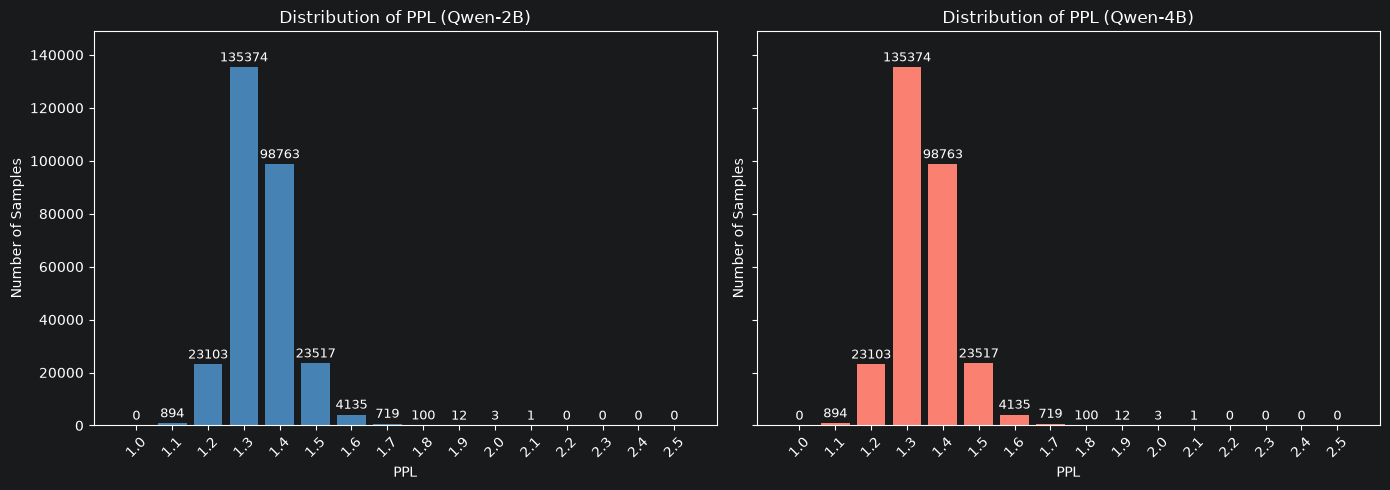

In [47]:
import matplotlib.pyplot as plt

# 各区间计数（PPL 从 1.0 到 2.9）
bins = [str(i / 10) for i in range(10, 26)]
counts_2b = [sum(1 for d in data_student if round(d["ppl"], 1) == i / 10) for i in range(10, 26)]
counts_4b = [sum(1 for d in data_student if round(d["ppl"], 1) == i / 10) for i in range(10, 26)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, counts, name, color in zip(
        axes,
        [counts_2b, counts_4b],
        ["Qwen-2B", "Qwen-4B"],
        ["steelblue", "salmon"],
):
    bars = ax.bar(bins, counts, color=color)
    # 在柱顶显示数值
    ax.bar_label(bars, labels=[str(c) for c in counts], padding=2, fontsize=9)
    ax.set_xlabel("PPL")
    ax.set_ylabel("Number of Samples")
    ax.set_title(f"Distribution of PPL ({name})")
    ax.margins(y=0.1)  # 给柱顶留出标注空间
    # 区间标签较密，可适当旋转
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [48]:
# average_confidence 的 3-sigma 边界
mean_confidence = sum(d["average_confidence"] for d in data_student) / len(data_student)
std_confidence = (sum((d["average_confidence"] - mean_confidence) ** 2 for d in data_student) / len(data_student)) ** 0.5
lower_bound = mean_confidence - 3 * std_confidence
upper_bound = mean_confidence + 3 * std_confidence
print(f"Average Confidence: {mean_confidence:.4f}")
print(f"3-sigma Lower Bound: {lower_bound:.4f}")
print(f"3-sigma Upper Bound: {upper_bound:.4f}")

Average Confidence: 0.8319
3-sigma Lower Bound: 0.7527
3-sigma Upper Bound: 0.9110


In [49]:
# PPL 的 3-sigma 边界
mean_ppl = sum(d["ppl"] for d in data_student) / len(data_student)
std_ppl = (sum((d["ppl"] - mean_ppl) ** 2 for d in data_student) / len(data_student)) ** 0.5
lower_bound = mean_ppl - 3 * std_ppl
upper_bound = mean_ppl + 3 * std_ppl
print(f"Average PPL: {mean_ppl:.4f}")
print(f"3-sigma Lower Bound: {lower_bound:.4f}")
print(f"3-sigma Upper Bound: {upper_bound:.4f}")

Average PPL: 1.3476
3-sigma Lower Bound: 1.1076
3-sigma Upper Bound: 1.5876


In [50]:
# average_confidence 小于等于 0.75 或者 PPL 大于等于 1.58 的 instance_id
bad_instance_ids = [d["instance_id"] for d in data_student if d["average_confidence"] <= 0.75 or d["ppl"] >= 1.58]
print(len(bad_instance_ids))

3146


In [51]:
with open("./exp/exp_local_qwen35_2B/bad_instance_ids.json", "w", encoding="utf-8") as f:
    json.dump(bad_instance_ids, f, ensure_ascii=False, indent=4)